In [8]:
# Practical 1: Regression Analysis
# Uber Fare Amount Prediction

# 1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

from geopy.distance import geodesic

# 2. Load the Uber Dataset
df_raw = pd.read_csv("uber.csv")
print(df_raw.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [9]:
# 3. Feature Engineering on pickup_datetime
df = df_raw.copy()
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['hour'] = df['pickup_datetime'].dt.hour
df['minute'] = df['pickup_datetime'].dt.minute
df['day'] = df['pickup_datetime'].dt.day
df['week'] = df['pickup_datetime'].dt.weekday
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

df = df.drop(columns=['Unnamed: 0', 'key', 'pickup_datetime'])
print(df.head())

   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  minute  day  week  month  year  
0         40.723217                1    19      52    7     3      5  2015  
1         40.750325                1    20       4   17     4      7  2009  
2         40.772647                1    21      45   24     0      8  2009  
3         40.803349                3     8      22   26     4      6  2009  
4         40.761247                5    17      47   28     3      8  2014  


In [10]:
# 4. Handling Null Values
print("Null counts:")
print(df.isnull().sum())
df = df.dropna()

Null counts:
fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
hour                 0
minute               0
day                  0
week                 0
month                0
year                 0
dtype: int64


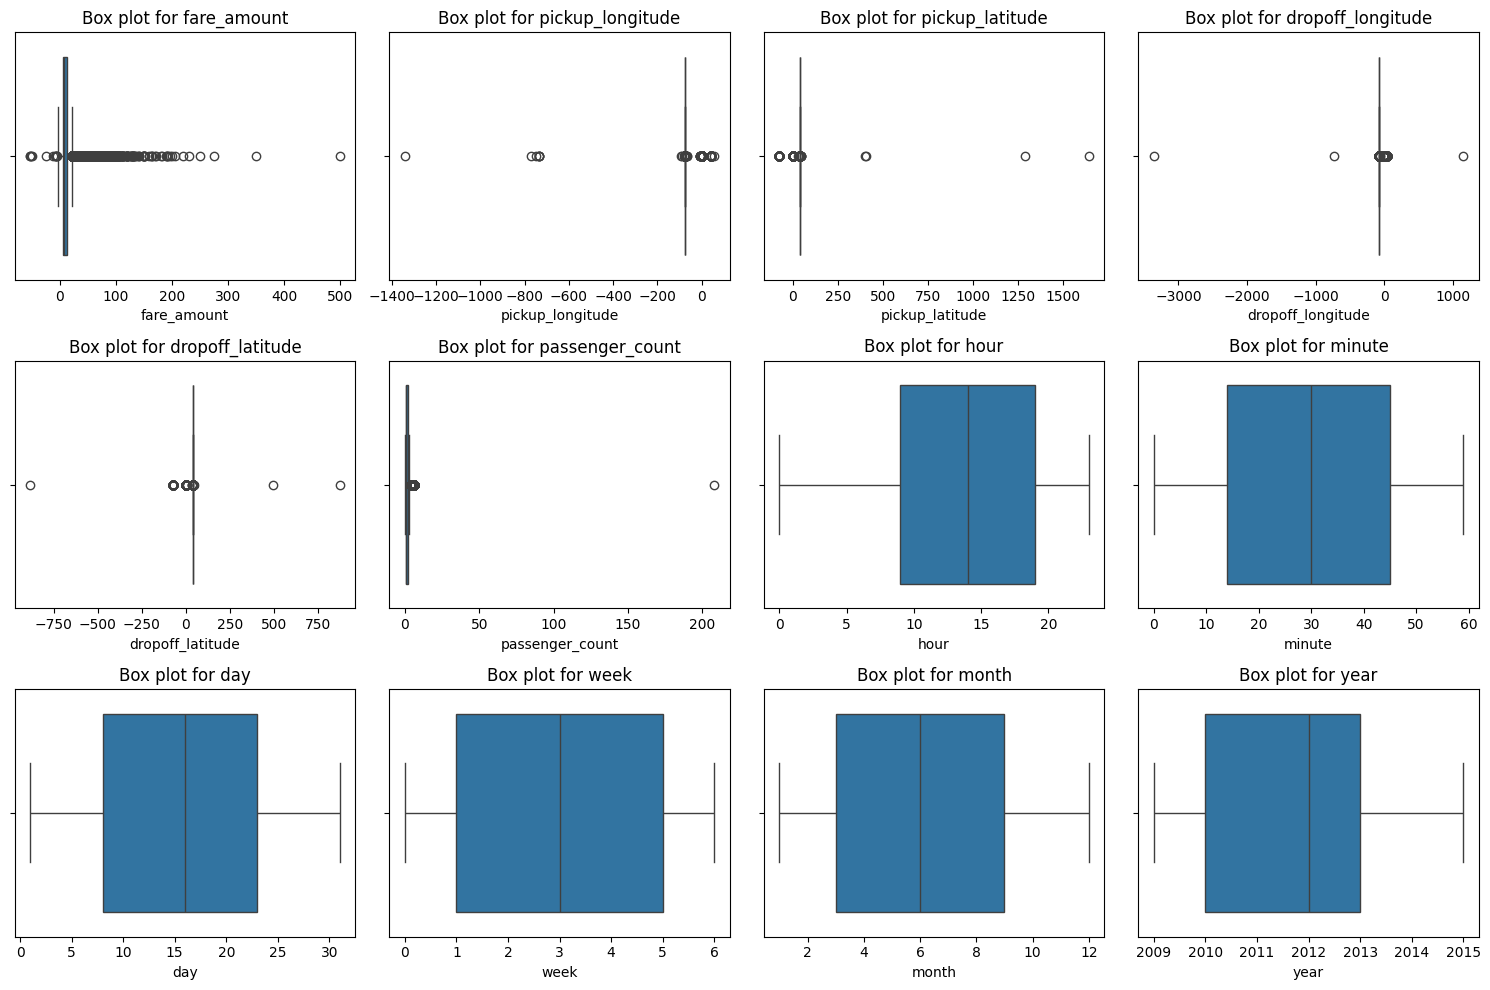

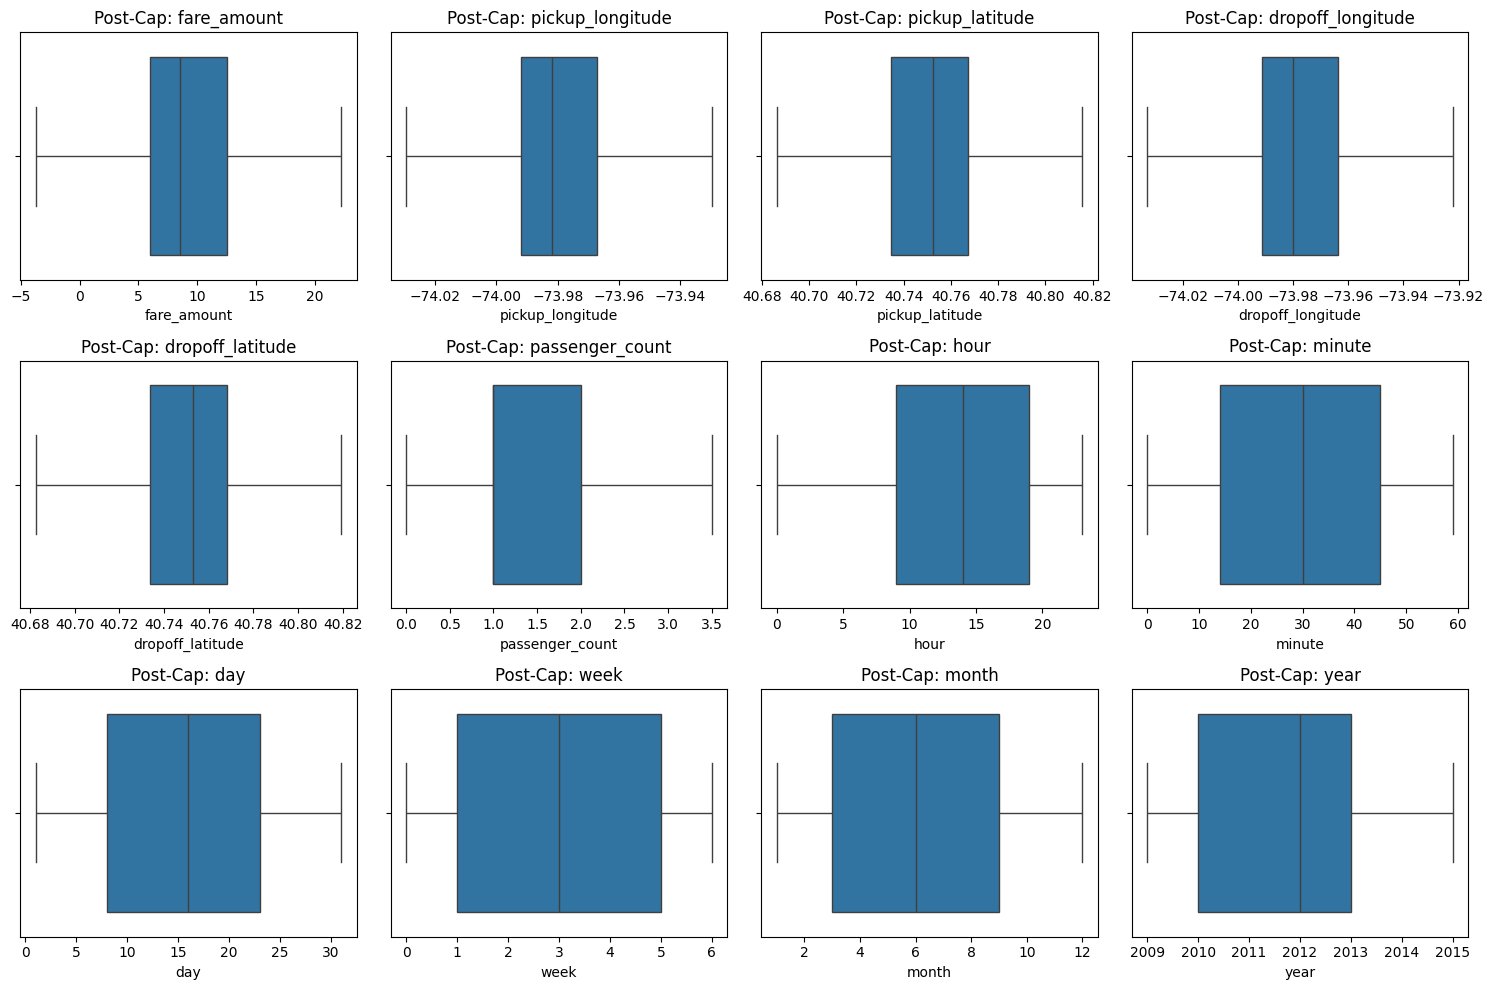

In [11]:
# 5 & 6. Detecting and Handling Outliers using IQR
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(df.select_dtypes(include=np.number).columns):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Box plot for {col}')
plt.tight_layout()
plt.show()

def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[column] = np.where(df[column] < lower_bound, lower_bound, df[column])
    df[column] = np.where(df[column] > upper_bound, upper_bound, df[column])
    return df

for col in df.select_dtypes(include=np.number).columns:
    df = cap_outliers(df, col)

# Boxplots after Handling Outliers
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(df.select_dtypes(include=np.number).columns):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Post-Cap: {col}')
plt.tight_layout()
plt.show()

In [12]:
# 7. Calculating Distance from Latitude and Longitude
def normalize_coordinates(lat, lon):
    lat = np.clip(lat, -90, 90)
    lon = ((lon + 180) % 360) - 180
    return lat, lon

df['pickup_latitude'], df['pickup_longitude'] = normalize_coordinates(df['pickup_latitude'], df['pickup_longitude'])
df['dropoff_latitude'], df['dropoff_longitude'] = normalize_coordinates(df['dropoff_latitude'], df['dropoff_longitude'])

# Geodesic distance calculation (in kilometers)
df['distance'] = df.apply(
    lambda row: geodesic(
        (row['pickup_latitude'], row['pickup_longitude']),
        (row['dropoff_latitude'], row['dropoff_longitude'])
    ).kilometers,
    axis=1
)

df = df.drop(columns=['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude'])
print(df.head())

   fare_amount  passenger_count  hour  minute   day  week  month    year  \
0          7.5              1.0  19.0    52.0   7.0   3.0    5.0  2015.0   
1          7.7              1.0  20.0     4.0  17.0   4.0    7.0  2009.0   
2         12.9              1.0  21.0    45.0  24.0   0.0    8.0  2009.0   
3          5.3              3.0   8.0    22.0  26.0   4.0    6.0  2009.0   
4         16.0              3.5  17.0    47.0  28.0   3.0    8.0  2014.0   

   distance  
0  1.681111  
1  2.454363  
2  5.039603  
3  1.661442  
4  4.123078  


In [13]:
# 8. Additional Feature Engineering
df['is_rush_hour'] = df['hour'].isin([18, 19, 20, 21, 22, 23]).astype(int)
df['is_late_night'] = df['hour'].isin([23, 0, 1]).astype(int)
df['is_early_morning'] = df['hour'].isin([3, 4, 5, 6]).astype(int)
df['is_weekend'] = df['week'].isin([5, 6]).astype(int)
df['is_weekday'] = df['week'].isin([0, 1, 2, 3, 4]).astype(int)
df['fare_per_km'] = df['fare_amount'].round(2) / df['distance'].round(2)

print(df.describe())

         fare_amount  passenger_count           hour         minute  \
count  199999.000000    199999.000000  199999.000000  199999.000000   
mean       10.081060         1.514375      13.491387      29.534848   
std         5.440199         0.876717       6.515505      17.335443   
min        -3.750000         0.000000       0.000000       0.000000   
25%         6.000000         1.000000       9.000000      14.000000   
50%         8.500000         1.000000      14.000000      30.000000   
75%        12.500000         2.000000      19.000000      45.000000   
max        22.250000         3.500000      23.000000      59.000000   

                 day           week          month           year  \
count  199999.000000  199999.000000  199999.000000  199999.000000   
mean       15.704739       3.048435       6.281791    2011.742434   
std         8.687377       1.946946       3.438933       1.856400   
min         1.000000       0.000000       1.000000    2009.000000   
25%         8.0

C:\Users\lalit\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


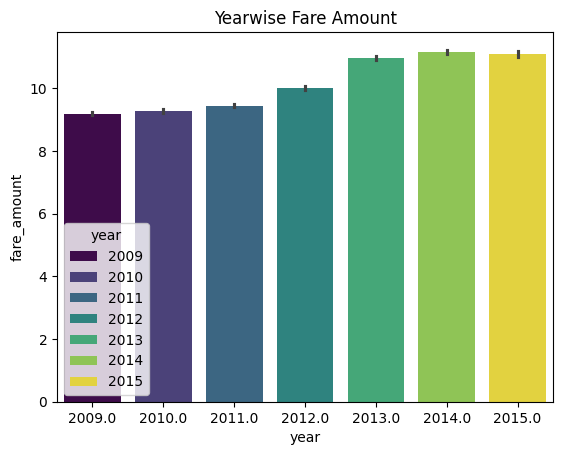

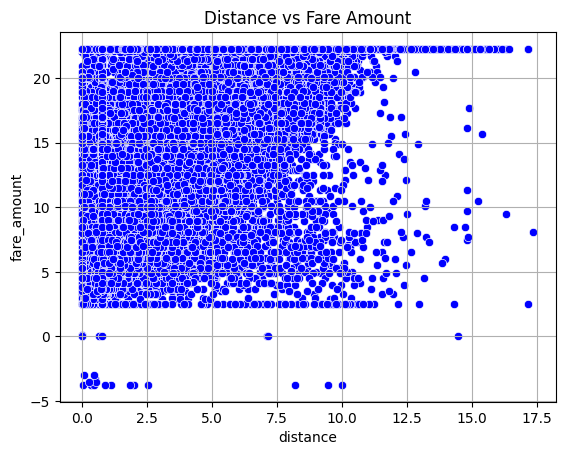

In [14]:
# 9 & 10. Exploratory Visualizations
sns.barplot(data=df, x='year', y='fare_amount', palette='viridis', hue='year')
plt.title("Yearwise Fare Amount")
plt.show()

sns.scatterplot(data=df, x='distance', y='fare_amount', color='blue')
plt.grid(True)
plt.title("Distance vs Fare Amount")
plt.show()

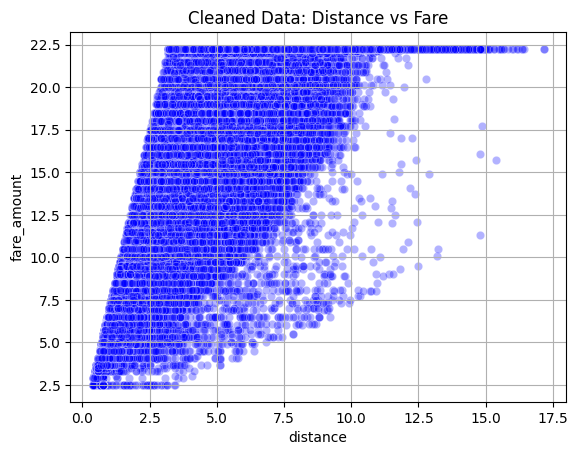

Original rows: 200000
After cleaning: 175518
Rows removed: 24482 (12.24%)


In [15]:
# 11 & 12. Filtering and Cleaning Data
df_cleaned = df.copy()
df_cleaned = df_cleaned[df_cleaned['fare_amount'] > 0]
df_cleaned = df_cleaned[~((df_cleaned['fare_amount'] > 100) & (df_cleaned['distance'] < 10))]
df_cleaned = df_cleaned[(df_cleaned['fare_per_km'] > 0.7) & (df_cleaned['fare_per_km'] <= 7)]

df_cleaned['log_fare'] = np.log1p(df_cleaned['fare_amount'])
df_cleaned['log_distance'] = np.log1p(df_cleaned['distance'])
df_cleaned['log_fare_per_km'] = np.log1p(df_cleaned['fare_per_km'])

sns.scatterplot(data=df_cleaned, x='distance', y='fare_amount', alpha=0.3, color='blue')
plt.grid(True)
plt.title("Cleaned Data: Distance vs Fare")
plt.show()

print(f"Original rows: {len(df_raw)}")
print(f"After cleaning: {len(df_cleaned)}")
print(f"Rows removed: {len(df_raw) - len(df_cleaned)} ({(1 - len(df_cleaned)/len(df_raw)) * 100:.2f}%)")

In [16]:
# 13. Splitting Data for Training and Testing
X = df_cleaned.drop(columns=['fare_amount', 'log_fare'])
y = df_cleaned['log_fare']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (140414, 16)
X_test shape: (35104, 16)


In [17]:
# 14 & 15. Training and Evaluating Regression Models
# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

# Lasso Regression
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)

def evaluate_model(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{model_name} - R2 Score: {r2:.4f}, RMSE: {rmse:.2f}")

evaluate_model(y_test, y_pred_lr, "Linear Regression")
evaluate_model(y_test, y_pred_ridge, "Ridge Regression")
evaluate_model(y_test, y_pred_lasso, "Lasso Regression")

Linear Regression - R2 Score: 0.9966, RMSE: 0.03
Ridge Regression - R2 Score: 0.9966, RMSE: 0.03
Lasso Regression - R2 Score: 0.7540, RMSE: 0.22


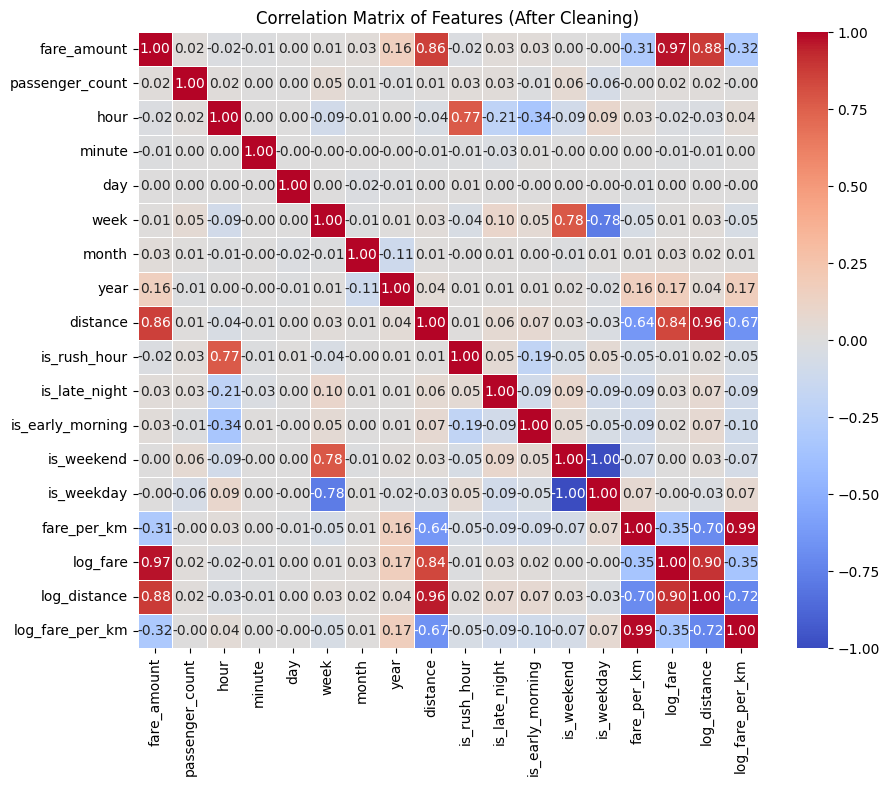

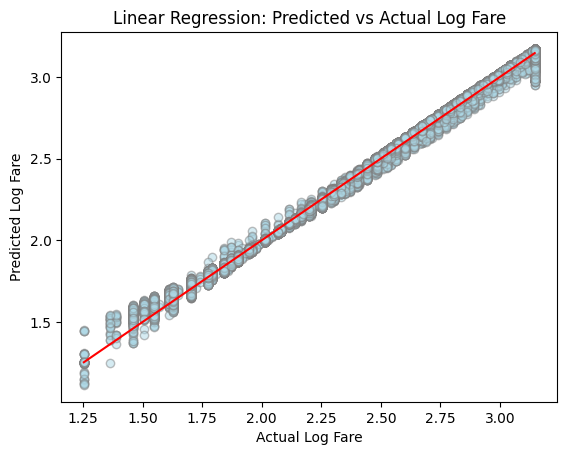

In [18]:
# 16 & 17. Correlation Heatmap and Final Evaluation Plot
correlation_matrix = df_cleaned.corr().round(2)
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Features (After Cleaning)')
plt.show()

plt.scatter(y_test, y_pred_lr, alpha=0.5, color='lightblue', edgecolor='gray')
plt.xlabel("Actual Log Fare")
plt.ylabel("Predicted Log Fare")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='solid')
plt.title("Linear Regression: Predicted vs Actual Log Fare")
plt.show()